# Machine Learning Practical · 03
## Regularisation, checkpointing and honest evaluation

Exercises for **L2-S61–L2-S80**: penalties, early stopping, capacity, learning curves,
checkpointing, metrics, repeated seeds, model selection and experiment records.

[Exercise guide](README.md) · [Worked laboratory](../ML_03_regularisation_and_selection.ipynb)

Python 3.11+; install `../requirements-notebook.txt`, then **Restart Kernel and Run All Cells**.
Every cell runs with the supplied baselines. **EDIT** cells and feedback guide your work;
saved outputs are starter results, not completed answers. The final test is disabled
until you explicitly release it after selecting a model. Allow 75–105 minutes.

**Deliverable:** a validation-only selection record, a verified restored checkpoint,
one final test report, and a short explanation of possible leakage in your workflow.

In [1]:
import copy, io, json, platform, time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import torch
from torch import nn
from IPython.display import display, Image

SEED = 4
RUN_MODE = "quick"                 # "quick" or "thorough"
assert RUN_MODE in {"quick", "thorough"}
FACTOR = 1 if RUN_MODE == "quick" else 2
START = time.perf_counter()
torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
versions = dict(python=platform.python_version(), numpy=np.__version__,
                matplotlib=matplotlib.__version__, torch=torch.__version__)
print(json.dumps(versions, indent=2))
print(f"CPU / float64 / seed {SEED} / {RUN_MODE} mode")

palette = {"navy": "#10243A", "teal": "#00A6A6", "orange": "#F28C45",
           "pink": "#DC4778", "blue": "#4878D0", "ink": "#183449", "muted": "#63788A"}
plt.rcParams.update({
    "figure.facecolor": "#F7FAFC", "axes.facecolor": "#F7FAFC",
    "axes.edgecolor": "#CAD6DF", "axes.labelcolor": palette["ink"],
    "text.color": palette["ink"], "xtick.color": palette["muted"],
    "ytick.color": palette["muted"], "font.size": 11,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "grid.color": "#DCE5EB", "grid.alpha": 0.65,
    "lines.linewidth": 2.3, "figure.dpi": 110, "legend.frameon": False,
    "font.family": "DejaVu Sans",
    "axes.prop_cycle": matplotlib.cycler(color=[palette[k] for k in
                                      ["teal", "orange", "pink", "blue", "navy"]]),
})

def show_figure(fig):
    """Embed a compact static PNG so GitHub can display the result."""
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

def signal(x):
    return np.sin(np.pi*x)

def sample_data(generator, n, sigma=0.05):
    x = np.sort(generator.uniform(0, 1, n))[:, None]
    y = signal(x) + sigma*generator.normal(size=x.shape)
    return x, y

def make_mlp(width=16, depth=2):
    layers = [nn.Linear(1, width), nn.Tanh()]
    for _ in range(depth-1):
        layers += [nn.Linear(width, width), nn.Tanh()]
    return nn.Sequential(*layers, nn.Linear(width, 1))

{
  "python": "3.13.9",
  "numpy": "2.4.2",
  "matplotlib": "3.10.8",
  "torch": "2.10.0"
}
CPU / float64 / seed 4 / quick mode


## A · Penalty conventions and exact zeros (L2-S61–L2-S64)

1. Implement soft thresholding for $\tfrac12\|b-z\|^2+\lambda_1\|b\|_1
   +\tfrac{\lambda_2}{2}\|b\|^2$. Plot coefficients as each penalty strength varies.
2. Identify exact zeros. Explain why L2 alone normally shrinks without producing zeros.
3. Derive how the threshold changes if the first term becomes $\|b-z\|^2/N$.
   State whether a neural penalty includes biases and how it is normalised.

<details><summary>Hint</summary>

Solve the scalar positive, negative and zero cases. For this half-squared-loss convention,
soft threshold by $\lambda_1$ and divide by $1+\lambda_2$.
</details>

In [2]:
z = np.array([-1.5, -.4, -.08, 0., .12, .7, 1.8])
# EDIT: replace the unpenalised baseline by the elastic-net minimiser.
def penalised_coefficients(z, lambda1, lambda2):
    return z.copy()

coefficient = penalised_coefficients(z, .3, .5)
print("Your coefficients:", coefficient)
print("Nonzero coefficients:", np.count_nonzero(coefficient))
# Scalar optimality conditions check both active and zero coordinates.
nonzero = np.abs(coefficient) > 1e-12
stationarity = coefficient-z+.5*coefficient+.3*np.sign(coefficient)
active_ok = np.all(np.abs(stationarity[nonzero]) < 1e-10)
zero_ok = np.all(np.abs(z[~nonzero]) <= .3+1e-10)
print("Penalty feedback:", "optimality conditions satisfied" if active_ok and zero_ok else "revise shrinkage rule")

Your coefficients: [-1.5  -0.4  -0.08  0.    0.12  0.7   1.8 ]
Nonzero coefficients: 6
Penalty feedback: revise shrinkage rule


## B · Restore the best validation checkpoint (L2-S65–L2-S71)

1. Replace `keep_checkpoint` so it saves a new checkpoint only when validation loss
   improves. Keep the deep copy and verify that the restored loss equals the minimum.
2. Compare widths 8 and 32, then one and two hidden layers. Plot both training and
   validation curves. Record the epoch selected; do not assume the final epoch wins.
3. Add an explicit L2 penalty to the **training** loss and compare two strengths.
   Validation must continue to use unpenalised prediction MSE.
4. Add a patience stopping rule as an extension. Restore the best state even when
   training ends because patience is exhausted.

<details><summary>Hint</summary>

Compare `current < best`. `copy.deepcopy(model.state_dict())` saves values;
`model.state_dict()` alone retains references to tensors that training keeps updating.
</details>

Stored epoch 500; restored validation 0.029916
Minimum observed validation 0.029330
Checkpoint feedback: the starter kept the last checkpoint; change the selection rule


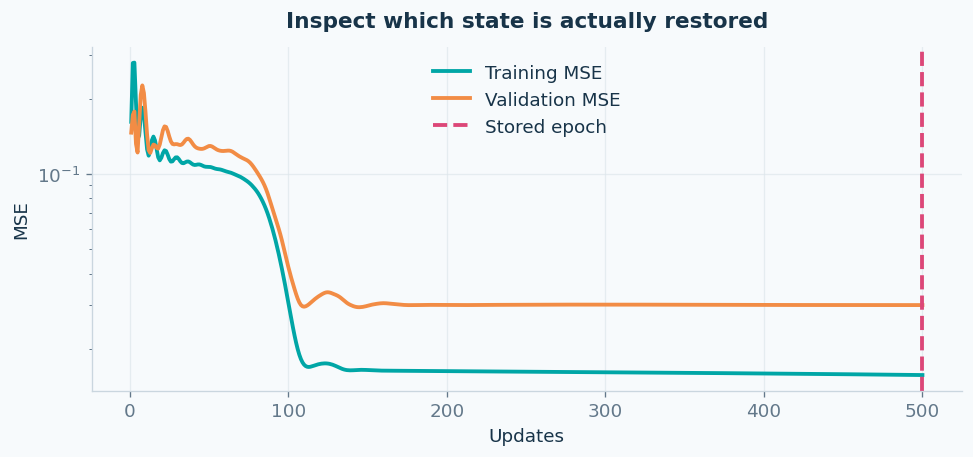

In [3]:
train_x, train_y = sample_data(np.random.default_rng(SEED), 24, .15)
val_x, val_y = sample_data(np.random.default_rng(SEED+1), 128, .15)
X, Y = torch.tensor(train_x), torch.tensor(train_y)
VX, VY = torch.tensor(val_x), torch.tensor(val_y)
# EDIT: the baseline always overwrites the checkpoint and therefore keeps the last model.
def keep_checkpoint(current, best):
    return True

def train_candidate(width, depth, seed, steps=400, l2=0.):
    torch.manual_seed(seed)
    model = make_mlp(width, depth)
    optimizer = torch.optim.Adam(model.parameters(), lr=.01)
    best_value, best_epoch, best_state = float("inf"), 0, None
    history = []
    for epoch in range(1, steps+1):
        optimizer.zero_grad(set_to_none=True)
        prediction_mse = (model(X)-Y).square().mean()
        # Explicit convention: half L2 norm of weight matrices; biases excluded.
        penalty = .5*l2*sum(p.square().sum() for name, p in model.named_parameters() if "weight" in name)
        loss = prediction_mse+penalty
        loss.backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            tr = (model(X)-Y).square().mean().item()
            va = (model(VX)-VY).square().mean().item()
        history.append((tr, va))
        if best_state is None or keep_checkpoint(va, best_value):
            best_value, best_epoch = va, epoch
            best_state = copy.deepcopy(model.state_dict())
        model.train()
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        restored = (model(VX)-VY).square().mean().item()
    return dict(model=model, history=np.asarray(history), validation=restored,
                checkpoint=best_epoch, seed=seed)

candidate = train_candidate(32, 2, SEED, steps=500*FACTOR)
observed_minimum = candidate["history"][:, 1].min()
print(f"Stored epoch {candidate['checkpoint']}; restored validation {candidate['validation']:.6f}")
print(f"Minimum observed validation {observed_minimum:.6f}")
print("Checkpoint feedback:", "best restored" if np.isclose(candidate["validation"], observed_minimum, rtol=1e-10)
      else "the starter kept the last checkpoint; change the selection rule")
fig, ax = plt.subplots(figsize=(8, 3.7), layout="constrained")
ax.semilogy(np.arange(1, len(candidate["history"])+1), candidate["history"][:, 0], label="Training MSE")
ax.semilogy(np.arange(1, len(candidate["history"])+1), candidate["history"][:, 1], label="Validation MSE")
ax.axvline(candidate["checkpoint"], color=palette["pink"], ls="--", label="Stored epoch")
ax.set(xlabel="Updates", ylabel="MSE", title="Inspect which state is actually restored")
ax.legend(); ax.grid(); show_figure(fig)

## C · Select with repeated seeds (L2-S66–L2-S71, L2-S75–L2-S76)

1. Complete B before using these results. Compare the predeclared candidate list below
   over three initialisation seeds. Keep data fixed across every run.
2. Replace `selected_index` by the index with the smallest **mean validation MSE**.
   Compare seed variability and parameter counts; do not select a lucky seed.
3. Average the three chosen models for the final predictor. Describe why this differs
   from reporting the mean test error of three separate models.
4. Before opening the test set, write your chosen architecture, penalty, budget,
   checkpoint rule and selection criterion in the answer cell below.

In [4]:
# EDIT: select by validation after finishing the checkpoint rule in B.
configurations = [(8, 1, 0.), (32, 2, 0.), (32, 2, .001)]
seeds = [4, 14, 24]
runs_by_configuration = []
validation_means = []
for width, depth, l2 in configurations:
    runs = [train_candidate(width, depth, seed, steps=400*FACTOR, l2=l2) for seed in seeds]
    values = np.array([run["validation"] for run in runs])
    runs_by_configuration.append(runs)
    validation_means.append(values.mean())
    print(f"{(width, depth, l2)}: validation mean {values.mean():.6f}; seed SD {values.std(ddof=1):.6f}")
selected_index = 0                 # baseline: first candidate, independent of scores
selected_runs = runs_by_configuration[selected_index]
print("Selected configuration:", configurations[selected_index])
print("Selection feedback:", "smallest mean validation" if selected_index == int(np.argmin(validation_means))
      else "implement the validation-based choice")
assert all(np.isfinite(validation_means))

(8, 1, 0.0): validation mean 0.034116; seed SD 0.006581


(32, 2, 0.0): validation mean 0.030768; seed SD 0.000744


(32, 2, 0.001): validation mean 0.028980; seed SD 0.000759
Selected configuration: (8, 1, 0.0)
Selection feedback: implement the validation-based choice


**Your frozen selection record:** state the candidate grid, repeated seeds, chosen
configuration, budget, checkpoint rule and whether the same validation set guided
several rounds of experimentation. Explain how a larger search can overfit validation.

## D · Final metrics, bugs and an experiment record (L2-S72–L2-S80)

1. After freezing C, set `RELEASE_TEST = True` once. Evaluate the chosen ensemble,
   reporting MSE, RMSE and MAE. Fill in `mae` below (the baseline incorrectly reuses RMSE).
2. Verify the metric formula directly, explain the units and check `RMSE >= MAE`.
3. Audit these potential bugs: preprocessing fit on all data; choosing epochs using
   test labels; prediction/label broadcasting; failing to clear gradients; and keeping
   a live reference to a checkpoint. State where your notebook prevents each relevant bug.
4. Complete the experiment record and write a final interpretation without changing
   settings in response to the test score. Further development needs a new final holdout.

<details><summary>Hint</summary>

MAE is the mean of absolute residuals. The inequality alone cannot detect the wrong
baseline, because equality is allowed; also compare directly with the defining formula.
</details>

In [5]:
# EDIT only after documenting the choice above. Run All keeps the holdout closed by default.
RELEASE_TEST = False
if RELEASE_TEST:
    test_x, test_y = sample_data(np.random.default_rng(SEED+1000), 1000, .15)
    with torch.no_grad():
        prediction = np.mean([run["model"](torch.tensor(test_x)).numpy()[:, 0]
                              for run in selected_runs], axis=0)
    residual = prediction-test_y[:, 0]
    mse = float(np.mean(residual**2))
    rmse = float(np.sqrt(mse))
    mae = rmse                    # EDIT: replace the baseline by the MAE formula
    print(dict(mse=mse, rmse=rmse, mae=mae))
    print("MAE feedback:", "definition matched" if np.isclose(mae, np.mean(np.abs(residual)), rtol=1e-10)
          else "RMSE and MAE are different metrics")
    assert rmse >= np.mean(np.abs(residual))-1e-12
    record = dict(data_seed=SEED, initialisation_seeds=seeds,
                  train_validation_test_sizes=[24, 128, 1000],
                  candidates=configurations, selected=configurations[selected_index],
                  updates_per_run=400*FACTOR, checkpoint_epochs=[r["checkpoint"] for r in selected_runs],
                  selected_validation_mean=validation_means[selected_index],
                  final_prediction="mean of selected models", mse=mse, rmse=rmse, mae=mae,
                  versions=versions)
    print(json.dumps(record, indent=2))
else:
    print("Test set remains closed. Finish the validation-based selection and record it before release.")

Test set remains closed. Finish the validation-based selection and record it before release.


**Your final interpretation:** discuss underfitting/overfitting, seed variability,
the difference between validation and test roles, and one limitation of this small study.

**Completion checklist:** penalty optimality conditions; lowest validation checkpoint
restored; configuration selected from repeated validation results; test released only
after freezing decisions; metric formulas checked; complete experiment record.

Next: [Chapter 3 practical exercises](../../3.%20Neural%20networks%20for%20solving%20PDEs/exercises/README.md).